In [193]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

target_freqs = [7.0, 12.0, 15.0, 17.0]
sr = 200
data = pd.read_csv('7Hz_T2.csv')
bp_low = int(min(target_freqs) - 3)  # Lowest flickering board frequency minus 3
bp_high = int(max(target_freqs) * 2 + 3)  # 2nd harmonic of the highest flickering board frequency plus 3
eeg_channels = ['Channel_1', 'Channel_2', 'Channel_3', 'Channel_4']
eeg_data = data[eeg_channels].values  # Shape: (n_samples, 4)
timestamps = np.arange(len(eeg_data)) / sr  # Assuming timestamps are sequential integers

In [194]:
from scipy.signal import butter, filtfilt, iirnotch

def bandpass_filter(data, lowcut, highcut, fs):
    nyquist = fs / 2
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(6, [low, high], btype='band')
    return filtfilt(b, a, data, axis=0)

def notch_filter(data, freq, fs):
    nyquist = fs / 2
    b, a = iirnotch(freq / nyquist, 30)
    return filtfilt(b, a, data, axis=0)

eeg_filtered = bandpass_filter(eeg_data, bp_low, bp_high, sr)
eeg_filtered = notch_filter(eeg_data, 50, sr)
print(eeg_filtered.shape)

(7486, 4)


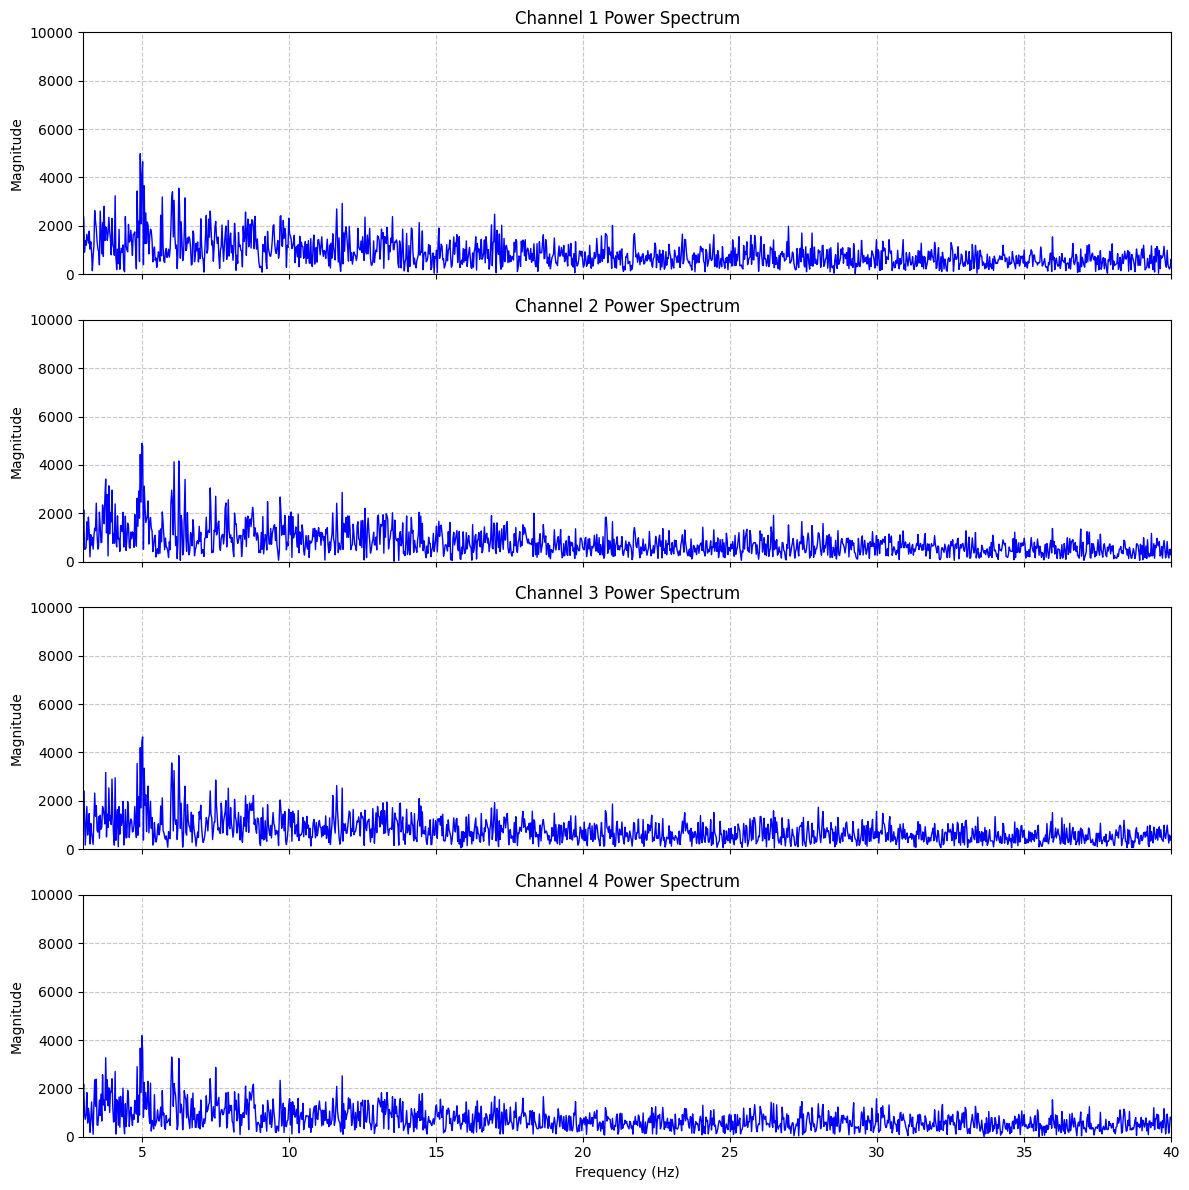

In [195]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq

# 1. Define signal parameters
sr = 200  # Sampling rate in Hz
n_samples = eeg_filtered.shape[0]
n_channels = eeg_filtered.shape[1]

# 2. Generate the frequency axis
# fftfreq returns both positive and negative frequencies
freqs = fftfreq(n_samples, 1/sr)

# We only need the positive half of the spectrum for plotting
pos_freqs = freqs[:n_samples//2]

# 3. Set up the plotting grid (4 rows, 1 column)
fig, axes = plt.subplots(n_channels, 1, figsize=(12, 12), sharex=True)

# 4. Loop through each channel, compute FFT, and plot
for ch in range(n_channels):
    # Extract the 1D array and remove any residual DC offset (mean centering)
    channel_data = eeg_filtered[:, ch]
    channel_data = channel_data - np.mean(channel_data)
    
    # Compute the 1D Discrete Fourier Transform
    fft_values = fft(channel_data)
    
    # Get the magnitude of the positive frequencies
    power_spectrum = np.abs(fft_values[:n_samples//2])
    
    # Plot from index 1 onward to explicitly drop the 0 Hz spike
    axes[ch].plot(pos_freqs[1:], power_spectrum[1:], color='b', linewidth=1)
    axes[ch].set_title(f'Channel {ch + 1} Power Spectrum')
    axes[ch].set_ylabel('Magnitude')
    axes[ch].grid(True, linestyle='--', alpha=0.7)
    axes[ch].set_xlim(3, 40)
    axes[ch].set_ylim(0, 10000)

# 5. Formatting
axes[-1].set_xlabel('Frequency (Hz)')

# Zoom in on the frequency band relevant to SSVEP (e.g., 0 to 50 Hz)
plt.tight_layout()
plt.show()

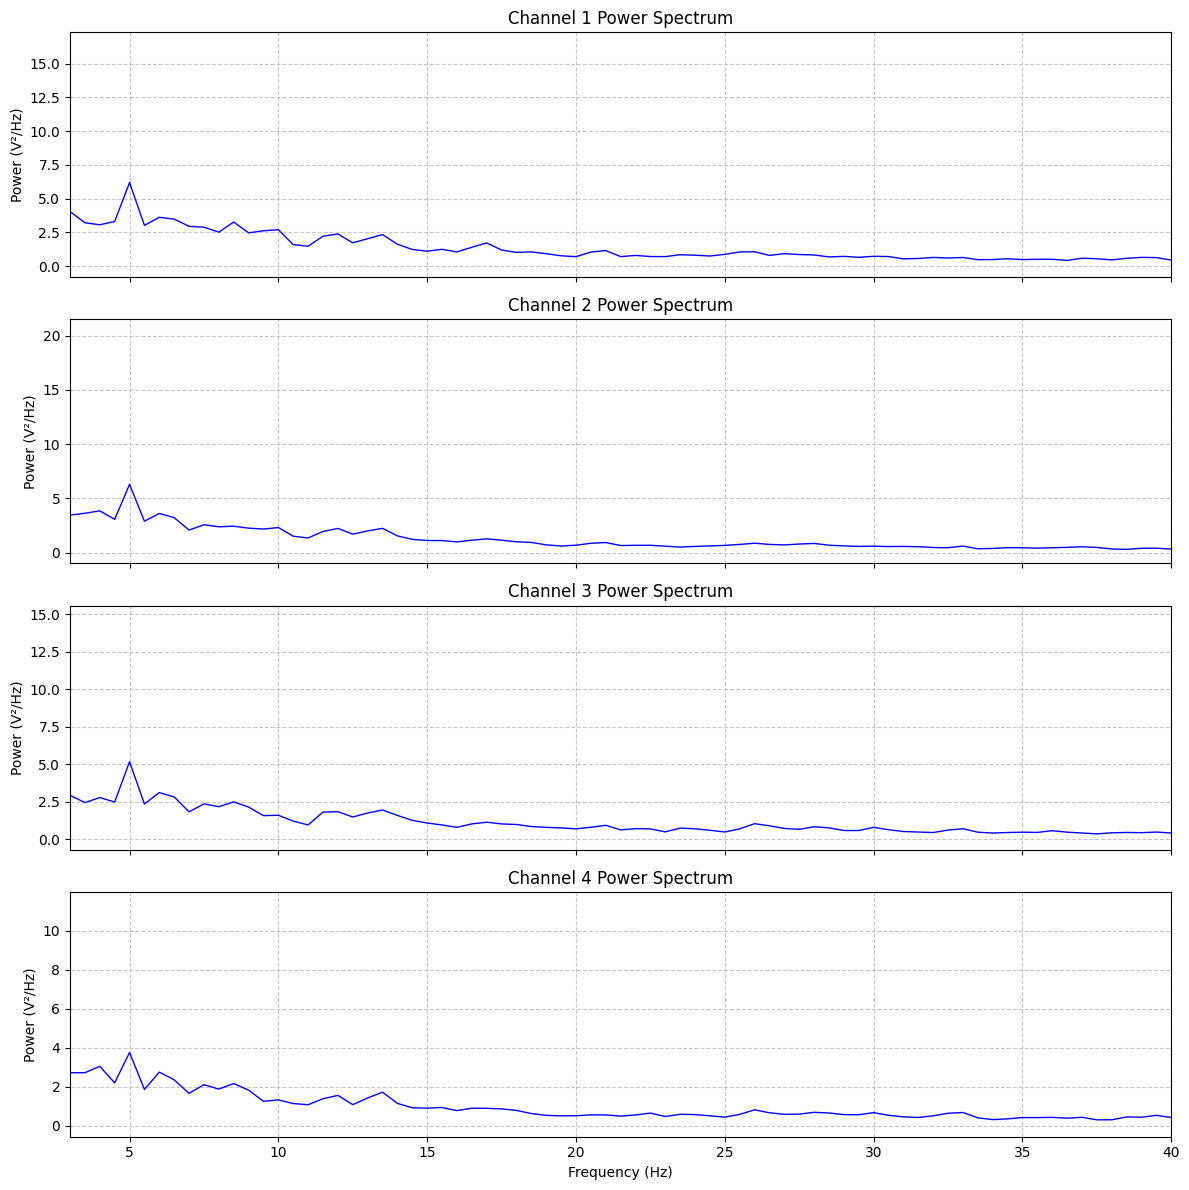

In [196]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

# 1. Define signal parameters
sr = 200  # Sampling rate in Hz
n_samples = eeg_filtered.shape[0]
n_channels = eeg_filtered.shape[1]

# 3. Set up the plotting grid (4 rows, 1 column)
fig, axes = plt.subplots(n_channels, 1, figsize=(12, 12), sharex=True)

# 4. Loop through each channel, compute Welch PSD, and plot
for ch in range(n_channels):
    # Extract the 1D array and remove any residual DC offset (mean centering)
    channel_data = eeg_filtered[:, ch]
    channel_data = channel_data - np.mean(channel_data)
    
    # Compute Welch's Power Spectral Density
    # nperseg can be adjusted (e.g., sr * 2 for 2-second windows / 0.5 Hz resolution)
    pos_freqs, power_spectrum = welch(channel_data, fs=sr, nperseg=sr*2)
    
    # Find the index where frequency > 0 to explicitly drop the 0 Hz spike
    non_zero_idx = pos_freqs > 0
    
    # Plot keeping the identical variable names
    axes[ch].plot(pos_freqs[non_zero_idx], power_spectrum[non_zero_idx], color='b', linewidth=1)
    axes[ch].set_title(f'Channel {ch + 1} Power Spectrum')
    axes[ch].set_ylabel('Power (V²/Hz)')  # Unit changes from Magnitude to PSD
    axes[ch].grid(True, linestyle='--', alpha=0.7)
    axes[ch].set_xlim(3, 40)


# 5. Formatting
axes[-1].set_xlabel('Frequency (Hz)')

# Zoom in on the frequency band relevant to SSVEP (e.g., 0 to 50 Hz)
plt.tight_layout()
plt.show()


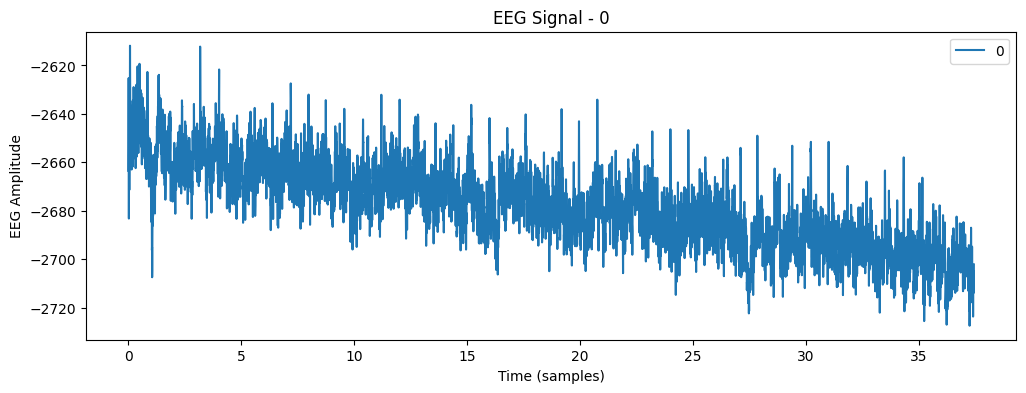

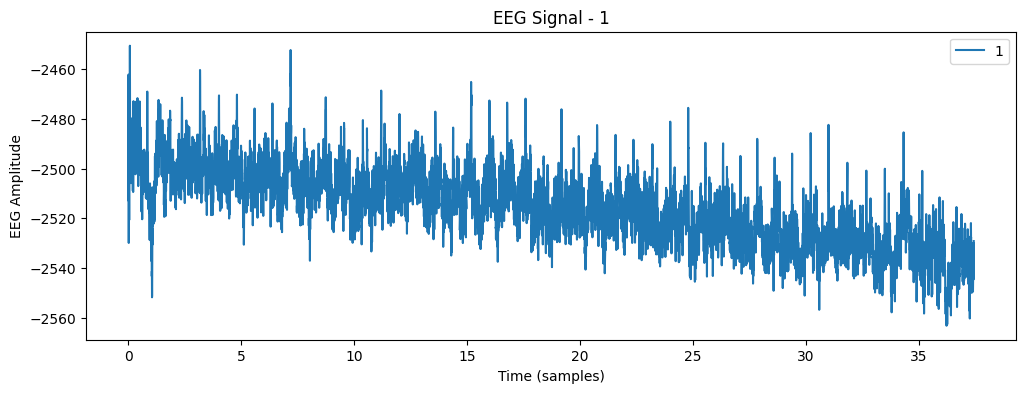

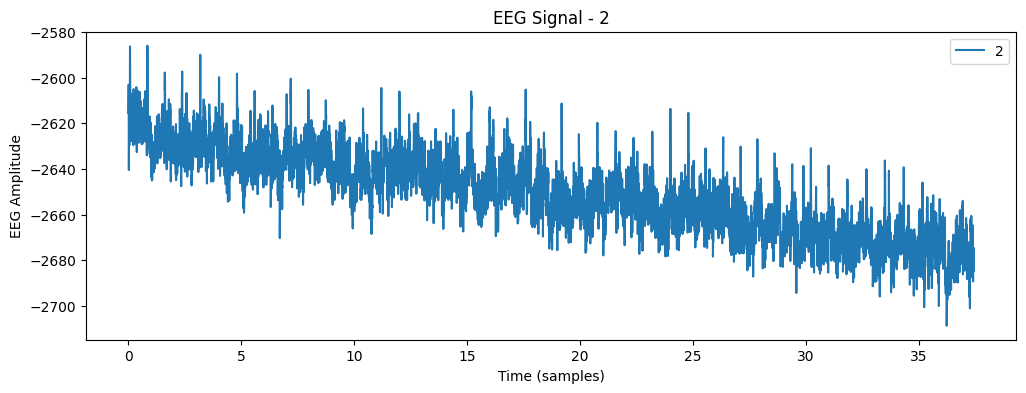

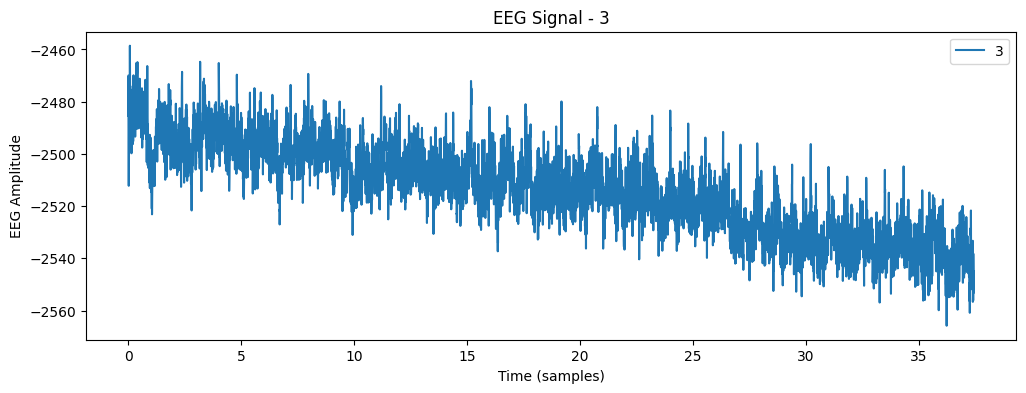

In [197]:
for channel in range(4):
    plt.figure(figsize=(12, 4))
    plt.plot(timestamps, eeg_filtered[:, channel], label=channel)
    plt.xlabel('Time (samples)')
    plt.ylabel('EEG Amplitude')
    plt.title(f'EEG Signal - {channel}')
    plt.legend()
    plt.show()


In [198]:
windows = []
window_size = 5 * sr  # seconds * 200 Hz
step_size = 5 * sr     # seconds * 200 Hz
    
# Added +1 to ensure the final window is captured if it fits perfectly
for start in range(0, len(eeg_filtered) - window_size + 1, step_size):
    end = start + window_size
    window = eeg_filtered[start:end, :]
    windows.append(window)

print(f"Created {len(windows)} windows")
print(f"Each window shape: {windows[0].shape}")

Created 7 windows
Each window shape: (1000, 4)


In [199]:
def SNR(power_spectrum, freqs, target_freq, n=2):
    """
    Calculate narrowband SNR at a target frequency.

    Parameters
    ----------
    power_spectrum : array
        Power at each frequency bin.
    freqs : array
        Frequencies corresponding to power_spectrum.
    target_freq : float
        Frequency where SNR is calculated.
    n : int
        Number of neighboring bins on EACH side used as noise.

    Returns
    -------
    snr : float
        SNR as a power ratio.
    """

    # Find FFT bin closest to target frequency
    idx = np.argmin(np.abs(freqs - target_freq))

    # Signal power: P(f)
    signal_power = power_spectrum[idx]

    # Neighboring bins
    lower = power_spectrum[idx-n:idx]
    upper = power_spectrum[idx+1:idx+n+1]

    # Noise estimate = average of 2n neighboring bins
    noise_power = np.mean(np.concatenate([lower, upper]))

    # Narrowband SNR
    snr = signal_power / noise_power

    return snr

Window 1 | Max Freq: 12.0 Hz | Gate Ratio: 2.91


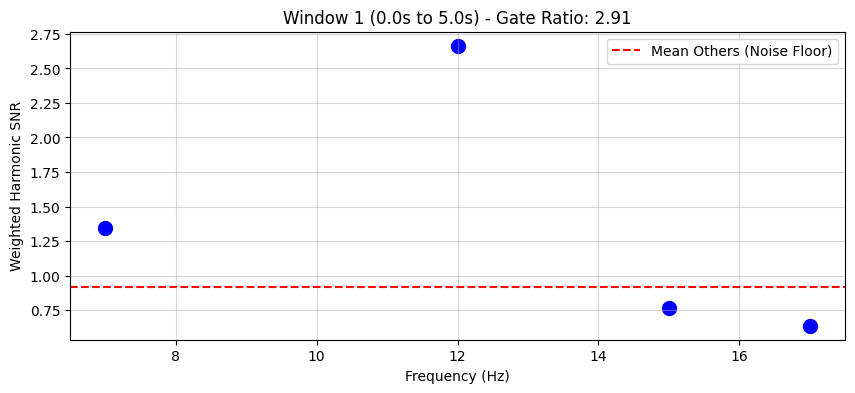

Window 2 | Max Freq: 17.0 Hz | Gate Ratio: 2.24


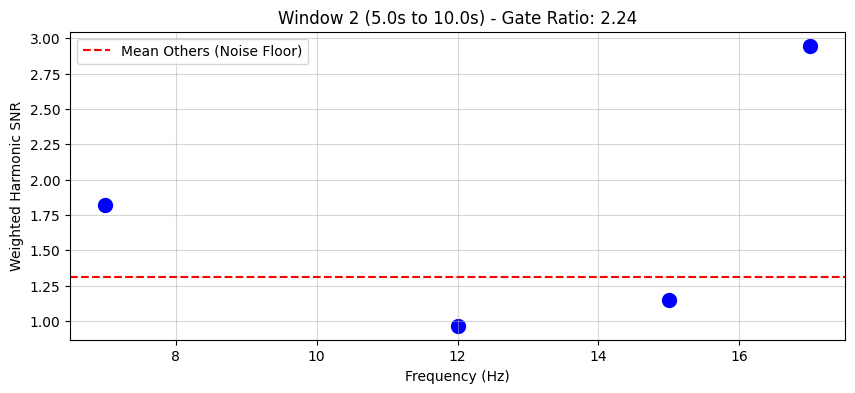

Window 3 | Max Freq: 12.0 Hz | Gate Ratio: 3.20


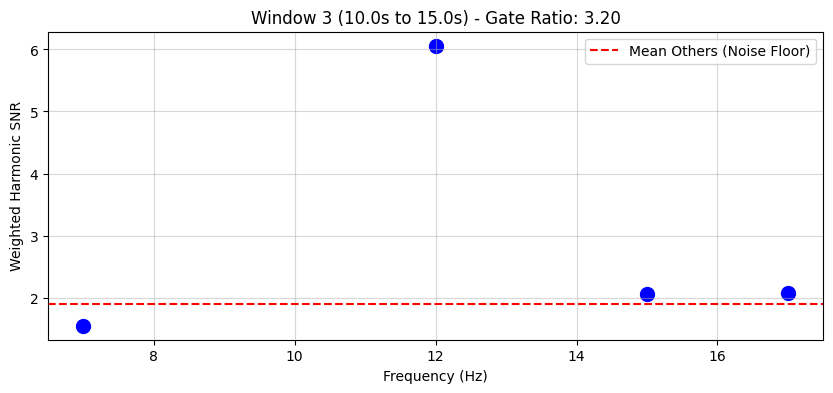

Window 4 | Max Freq: 17.0 Hz | Gate Ratio: 1.40


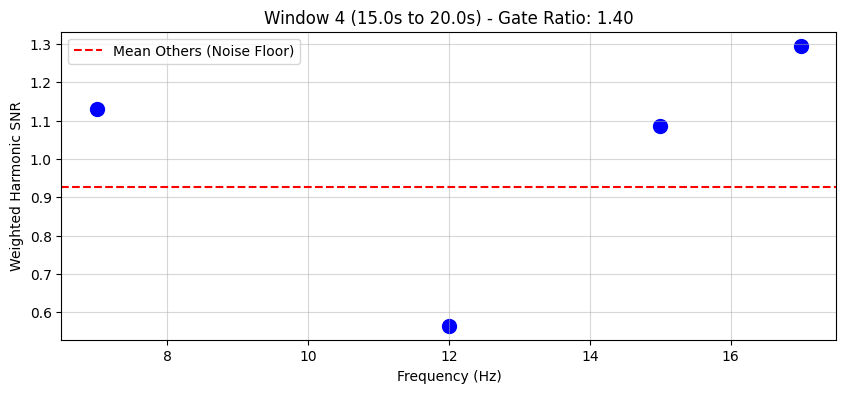

Window 5 | Max Freq: 15.0 Hz | Gate Ratio: 1.67


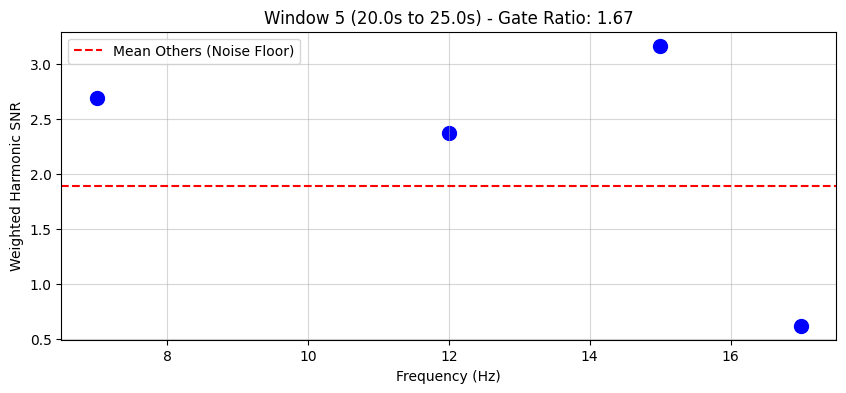

Window 6 | Max Freq: 17.0 Hz | Gate Ratio: 3.57


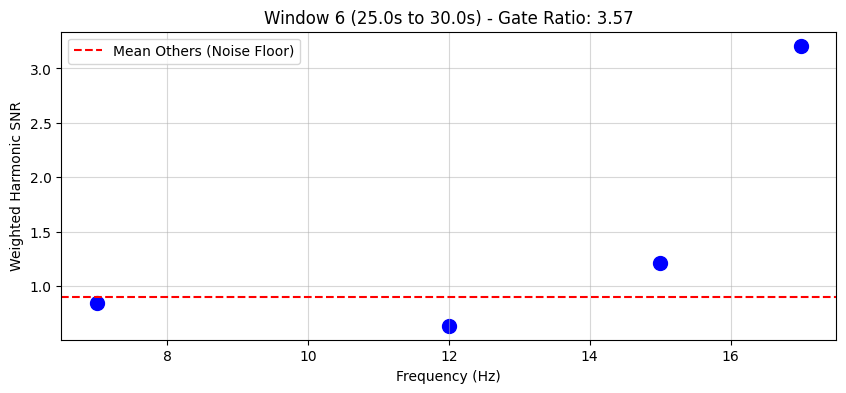

Window 7 | Max Freq: 12.0 Hz | Gate Ratio: 1.52


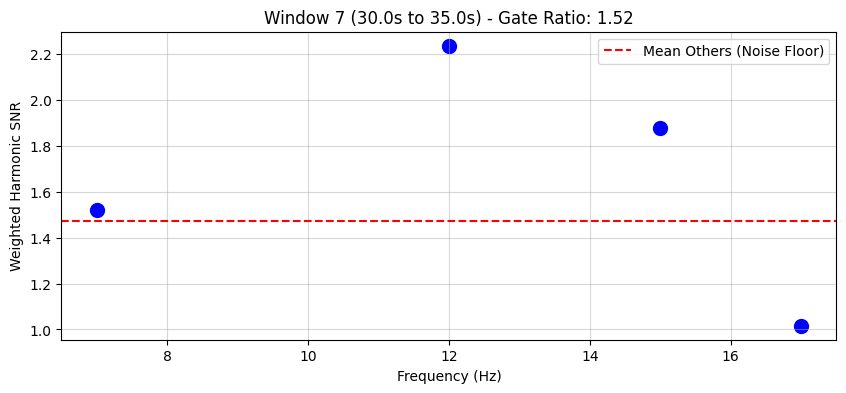

In [200]:
from scipy.fft import fft, fftfreq
import numpy as np
import matplotlib.pyplot as plt

# Assuming 'windows' and 'sr' are defined earlier
n_samples = windows[0].shape[0]
n_channels = windows[0].shape[1]

# 1. Define Fixed Channel Weights (e.g., O1, O2 get 70% of the weight, PO7, PO8 get 30%)
# Adjust the index positions to match your actual data array order
channel_weights = np.array([0.15, 0.35, 0.35, 0.15])

# Placeholder for your SNR function (ensure this matches your actual implementation)
def SNR(power_spec, freqs, target, n=3):
    idx = np.argmin(np.abs(freqs - target))
    signal = power_spec[idx]
    # Simple neighborhood mean for noise (excluding the target bin)
    noise_bins = np.concatenate([power_spec[max(0, idx-n):idx], power_spec[idx+1:idx+1+n]])
    noise = np.mean(noise_bins) if len(noise_bins) > 0 else 1e-6
    return signal / noise

gate_ratios = []

# Process and plot each window separately
for i, window in enumerate(windows):
    # window_powers will store a list of 4 channel scores for each frequency
    window_powers = {freq: [] for freq in target_freqs}
    
    for ch in range(n_channels):
        channel_data = window[:, ch]
        # Mean centering to remove DC offset
        channel_data = channel_data - np.mean(channel_data)
        
        fft_values = fft(channel_data)
        fft_freqs = fftfreq(n_samples, 1/sr)
        
        power_spectrum = np.abs(fft_values[:n_samples//2]) ** 2
        positive_freqs = fft_freqs[:n_samples//2]
        
        n = 3
        for target_freq in target_freqs:
            snr_1 = SNR(power_spectrum, positive_freqs, target_freq * 1, n=n)
            snr_2 = SNR(power_spectrum, positive_freqs, target_freq * 2, n=n)
            
            # Harmonic Summation
            H_snr = snr_1 + 0.5 * snr_2
            window_powers[target_freq].append(H_snr)

    # 2. Weighted Average across channels for this window
    weighted_avg_powers = [np.average(window_powers[freq], weights=channel_weights) for freq in target_freqs]
    
    # 3. Calculate the Gate Ratio
    max_score = np.max(weighted_avg_powers)
    max_idx = np.argmax(weighted_avg_powers)
    
    # Extract the scores of the non-target frequencies to find the noise floor
    other_scores = [score for j, score in enumerate(weighted_avg_powers) if j != max_idx]
    mean_other_scores = np.mean(other_scores)
    
    gate_ratio = max_score / mean_other_scores
    gate_ratios.append(gate_ratio)
    
    # Print the Gate Ratio for observation
    print(f"Window {i+1} | Max Freq: {target_freqs[max_idx]} Hz | Gate Ratio: {gate_ratio:.2f}")
    
    # Optional: Plotting
    start_time = (i * step_size) / sr if 'step_size' in locals() else 0
    end_time = start_time + (n_samples / sr)
    
    plt.figure(figsize=(10, 4))
    plt.scatter(target_freqs, weighted_avg_powers, marker='o', c='b', s=100)
    plt.axhline(mean_other_scores, color='r', linestyle='--', label=f'Mean Others (Noise Floor)')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Weighted Harmonic SNR')
    plt.title(f'Window {i+1} ({start_time:.1f}s to {end_time:.1f}s) - Gate Ratio: {gate_ratio:.2f}')
    plt.grid(True, alpha=0.5)
    plt.legend()
    plt.show()

# After the loop, you can analyze `gate_ratios` to find your resting state threshold
# e.g., threshold = np.mean(resting_gate_ratios) + 2.5 * np.std(resting_gate_ratios)

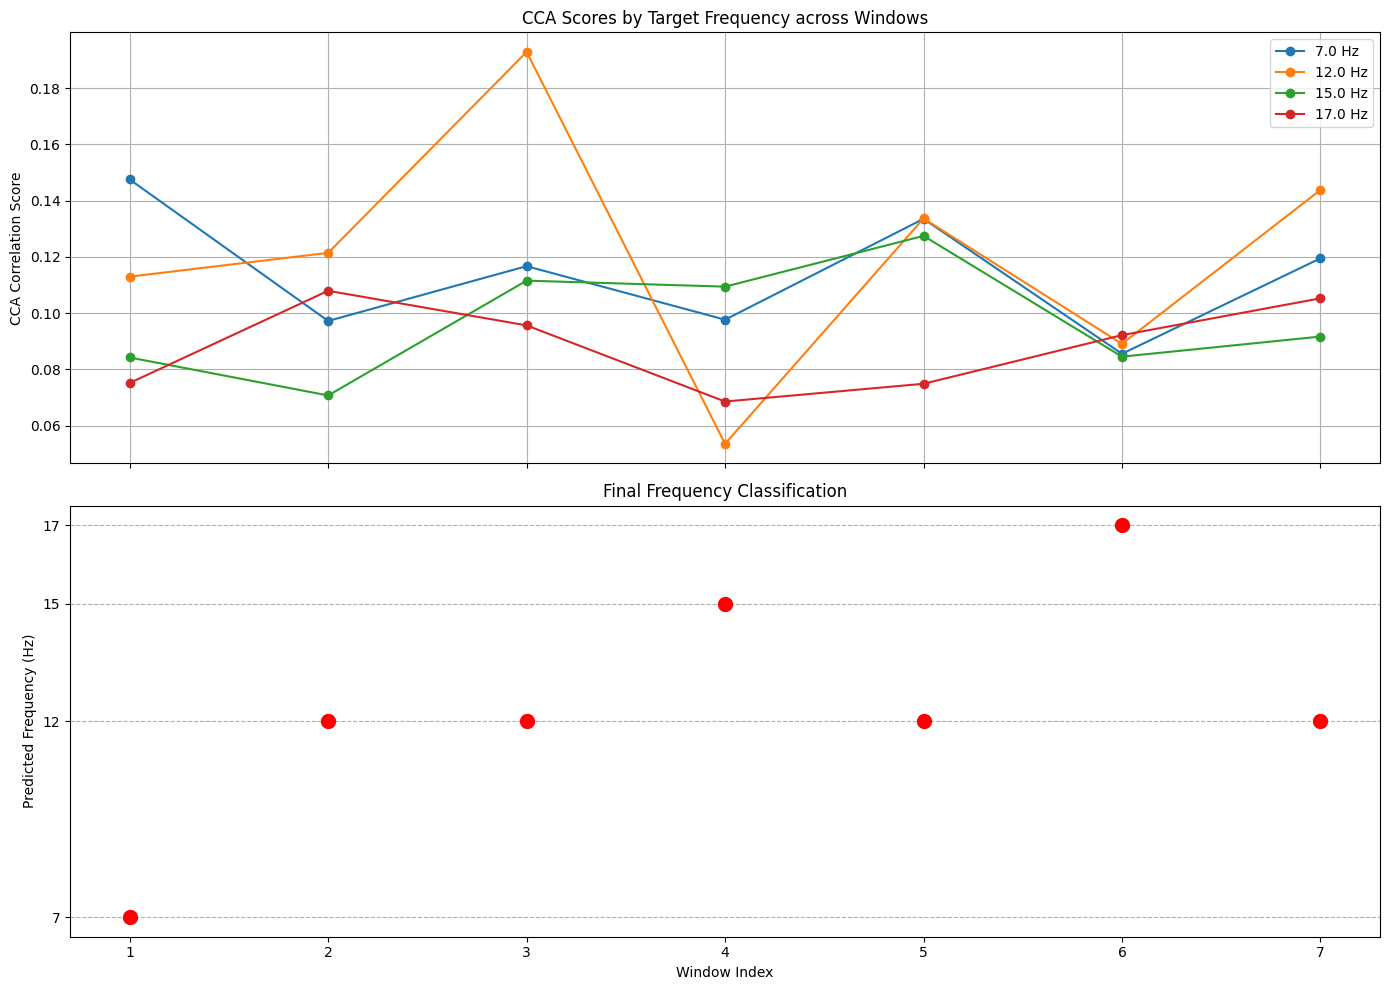

In [201]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cross_decomposition import CCA

# 1. Define CCA Parameters
n_harmonics = 2  # Usually 2 to 4 harmonics yield the best accuracy
sr = 200
n_samples = windows[0].shape[0]
t = np.arange(n_samples) / sr

# 2. Generate Reference Signals (Sine/Cosine templates)
def generate_reference_signals(freqs, time_vector, harmonics):
    Y_refs = {}
    for f in freqs:
        y_f = []
        for h in range(1, harmonics + 1):
            y_f.append(np.sin(2 * np.pi * h * f * time_vector))
            y_f.append(np.cos(2 * np.pi * h * f * time_vector))
        Y_refs[f] = np.array(y_f).T  # Shape: (n_samples, 2 * harmonics)
    return Y_refs

Y_ref = generate_reference_signals(target_freqs, t, n_harmonics)

# 3. Apply CCA to each window
predicted_freqs = []
cca_score_matrix = []

# n_components=1 because we only care about the highest correlation pair
cca = CCA(n_components=1)

for window in windows:
    window_scores = []
    
    for f in target_freqs:
        Y = Y_ref[f]
        
        # Fit CCA on the EEG window (X) and the reference signals (Y)
        cca.fit(window, Y)
        X_c, Y_c = cca.transform(window, Y)
        
        # Calculate Pearson correlation of the first canonical variables
        corr = np.corrcoef(X_c[:, 0], Y_c[:, 0])[0, 1]
        window_scores.append(corr)
        
    cca_score_matrix.append(window_scores)
    
    # Classify as the frequency with the maximum correlation score
    best_freq_idx = np.argmax(window_scores)
    predicted_freqs.append(target_freqs[best_freq_idx])

# 4. Plot the CCA Scores and Predicted Frequencies
cca_score_matrix = np.array(cca_score_matrix)
window_indices = np.arange(1, len(windows) + 1)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Top Plot: Line chart of CCA scores for all frequencies over time
for i, f in enumerate(target_freqs):
    ax1.plot(window_indices, cca_score_matrix[:, i], marker='o', label=f'{f} Hz')

ax1.set_ylabel('CCA Correlation Score')
ax1.set_title('CCA Scores by Target Frequency across Windows')
ax1.legend()
ax1.grid(True)

# Bottom Plot: Scatter plot of the final predicted frequency
ax2.scatter(window_indices, predicted_freqs, c='red', s=100, zorder=5)
ax2.set_yticks(target_freqs)
ax2.set_xlabel('Window Index')
ax2.set_ylabel('Predicted Frequency (Hz)')
ax2.set_title('Final Frequency Classification')
ax2.grid(True, axis='y', linestyle='--')

plt.tight_layout()
plt.show()